# EDA & Data Cleaning: WM 2026 (Challenge C)

An overview of the data: what is in the raw files, how clean they are, and what the cleaning step does.

1. Load the raw data
2. Data quality (missing values, duplicates, keys, consistency between sources)
3. Plausibility of the match data
4. Distributions of the team variables
5. Relationships between predictors
6. Matches: goals, results, value gap
7. Cleaning: the cleaning logic lives in `src/build_dataset.py`. This notebook only calls it and checks the output, so the logic exists in one place.

The raw files in `data/raw/` are never modified.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

ROOT = Path.cwd().resolve()
ROOT = ROOT.parent if ROOT.name == "notebooks" else ROOT
sys.path.insert(0, str(ROOT / "src"))
import build_dataset as bd  # the single source of truth for cleaning

RAW = ROOT / "data" / "raw"
pd.set_option("display.max_columns", 30, "display.width", 160)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

## 1. Raw data

| File | Source | Grain |
|---|---|---|
| `World Cup 2026.csv` | Kaggle `khayalmammadov/...` | 1 row per team, snapshot **before** the tournament (April 2026) |
| `matches.csv` | Kaggle `mann14/...` | 1 row per match (104) |
| `teams.csv` | Kaggle `mann14/...` | 1 row per team, incl. elimination round |

In [2]:
pre = pd.read_csv(RAW / "fifa-world-cup-2026-48-teams-dataset" / "World Cup 2026.csv", encoding="utf-8-sig")
matches = pd.read_csv(RAW / "2026-fifa-world-cup" / "matches.csv")
res_teams = pd.read_csv(RAW / "2026-fifa-world-cup" / "teams.csv")

for name, d in [("pre-tournament", pre), ("matches", matches), ("teams (results)", res_teams)]:
    print(f"{name:16s} {d.shape[0]:>4} rows × {d.shape[1]:>2} cols")

pre-tournament     48 rows × 22 cols
matches           104 rows × 11 cols
teams (results)    48 rows ×  6 cols


In [3]:
pre.head()

,Team,Group,Confederation,FIFA Ranking,World Cup Appearances,World Titles,Best Result,Last WC Result,Star Player,Squad Market Value (€m),Group Stage Qual. (%),Championship Prob. (%),First Appearance,Championship Category,Group Opponent 1,Group Opponent 2,Group Opponent 3,Group Strongest Team,Confederation Team Count,Confederation Avg FIFA Ranking,Confederation Total Market Value (€m),Confederation World Titles
0,France,I,UEFA,1,16,2,Champion,Final,Kylian Mbappe,1580,93,22.2,No,Favorite,Norway,Senegal,Iraq,France,16,22.25,11350,13
1,Spain,H,UEFA,2,16,1,Champion,Champion,Lamine Yamal,1250,92,20.0,No,Favorite,Uruguay,Saudi Arabia,Cape Verde,Spain,16,22.25,11350,13
2,Argentina,J,CONMEBOL,3,19,3,Champion,Champion,Lionel Messi,980,88,12.5,No,Strong Contender,Austria,Algeria,Jordan,Argentina,6,21.17,3890,10
3,England,L,UEFA,4,17,1,Champion,Final,Jude Bellingham,1250,90,15.4,No,Favorite,Croatia,Panama,Ghana,England,16,22.25,11350,13
4,Portugal,K,UEFA,5,9,0,Semifinal,Quarterfinal,Cristiano Ronaldo,980,90,11.1,No,Strong Contender,Colombia,DR Congo,Uzbekistan,Portugal,16,22.25,11350,13


In [4]:
pre.dtypes.to_frame('dtype').T

,Team,Group,Confederation,FIFA Ranking,World Cup Appearances,World Titles,Best Result,Last WC Result,Star Player,Squad Market Value (€m),Group Stage Qual. (%),Championship Prob. (%),First Appearance,Championship Category,Group Opponent 1,Group Opponent 2,Group Opponent 3,Group Strongest Team,Confederation Team Count,Confederation Avg FIFA Ranking,Confederation Total Market Value (€m),Confederation World Titles
dtype,str,str,str,int64,int64,int64,str,str,str,int64,int64,float64,str,str,str,str,str,str,int64,float64,int64,int64


The last eight columns of `pre` (`Group Opponent 1–3`, `Group Strongest Team`, `Confederation …`) are **derived**: they can be computed from group or confederation and add no new information. The analysis mainly needs **market value, FIFA ranking and bookmaker probabilities**.

In [5]:
matches.head()

,match_id,date,stage,group,team_1,team_2,score_1,score_2,winner,decided_by_penalties,notes
0,1,2026-06-11,Group Stage,A,Mexico,South Africa,2,0,Mexico,No,Tournament opening match at Estadio Azteca
1,2,2026-06-11,Group Stage,A,South Korea,Czechia,2,1,South Korea,No,NaN
2,3,2026-06-12,Group Stage,B,Canada,Bosnia and Herzegovina,1,1,Draw,No,NaN
3,4,2026-06-12,Group Stage,D,United States,Paraguay,4,1,United States,No,NaN
4,5,2026-06-13,Group Stage,B,Switzerland,Qatar,1,1,Draw,No,NaN


In [6]:
res_teams.head()

,team,group,confederation,host_nation,world_cup_debut,eliminated_round
0,Mexico,A,CONCACAF,Yes,No,Round of 16
1,South Korea,A,AFC,No,No,Group Stage
2,Czechia,A,UEFA,No,No,Group Stage
3,South Africa,A,CAF,No,No,Group Stage
4,Canada,B,CONCACAF,Yes,No,Round of 16


## 2. Data quality

In [7]:
def profile(d):
    return pd.DataFrame({"dtype": d.dtypes.astype(str), "missing": d.isna().sum(),
                         "unique": d.nunique()})

print("Duplicate rows:", {n: int(d.duplicated().sum()) for n, d in
                          [("pre", pre), ("matches", matches), ("res_teams", res_teams)]})
profile(matches)

Duplicate rows: {'pre': 0, 'matches': 0, 'res_teams': 0}


,dtype,missing,unique
match_id,int64,0,104
date,str,0,34
stage,str,0,7
group,str,32,12
team_1,str,0,39
team_2,str,0,47
score_1,int64,0,8
score_2,int64,0,5
winner,str,0,35
decided_by_penalties,str,0,2


Missing values occur only in `matches`, and both cases are structural:
- `group` is empty for the 32 knockout matches, which is correct.
- `notes` is a free-text comment, filled in for only 18 matches.

`pre` and `res_teams` are complete.

In [8]:
# Keys: team names must match across all three sources
pre_teams, res_set = set(pre.Team), set(res_teams.team)
match_teams = set(matches.team_1) | set(matches.team_2)
print("only in pre-tournament:", pre_teams - res_set)
print("only in results:       ", res_set - pre_teams)
print("match teams ⊆ results: ", match_teams <= res_set)

only in pre-tournament: {'Bosnia & Herz.'}
only in results:        {'Bosnia and Herzegovina'}
match teams ⊆ results:  True


**Finding 1:** Bosnia is spelled `Bosnia & Herz.` in the pre-tournament source but `Bosnia and Herzegovina` in the results data. Without a fix, the join would drop a team. → The cleaning renames it (`bd.NAME_FIX`).

In [9]:
fixed = pre.assign(Team=pre.Team.replace(bd.NAME_FIX))
x = fixed.merge(res_teams, left_on="Team", right_on="team", validate="1:1")
print("joined teams:", len(x))
print("group mismatches:        ", (x.Group != x.group).sum())
print("confederation mismatches:", (x.Confederation != x.confederation).sum())

joined teams: 48
group mismatches:         0
confederation mismatches: 0


After the rename, all 48 teams join 1:1, and group and confederation agree between the two sources.

## 3. Plausibility of the match data

In [10]:
expected = {"Group Stage": 72, "Round of 32": 16, "Round of 16": 8, "Quarterfinal": 4,
            "Semifinal": 2, "Third Place Match": 1, "Final": 1}
counts = matches.stage.value_counts().reindex(expected)
pd.DataFrame({"observed": counts, "expected (48-team format)": pd.Series(expected)})

,observed,expected (48-team format)
Group Stage,72,72
Round of 32,16,16
Round of 16,8,8
Quarterfinal,4,4
Semifinal,2,2
Third Place Match,1,1
Final,1,1


In [11]:
long = pd.concat([matches[["stage", "team_1"]].rename(columns={"team_1": "team"}),
                  matches[["stage", "team_2"]].rename(columns={"team_2": "team"})])
gpt = long[long.stage == "Group Stage"].team.value_counts()
print("every team plays exactly 3 group matches:", gpt.eq(3).all() and len(gpt) == 48)

ko = matches[matches.stage != "Group Stage"]
draw_ko = ko[ko.score_1 == ko.score_2]
print("KO matches level after 90/120 min:", len(draw_ko),
      "| all flagged as penalties:", draw_ko.decided_by_penalties.eq("Yes").all(),
      "| all have a winner:", (draw_ko.winner != "Draw").all())

grp = matches[matches.stage == "Group Stage"]
print("group 'Draw' label consistent with score:", (grp.winner.eq("Draw") == grp.score_1.eq(grp.score_2)).all())
draw_ko[["stage", "team_1", "team_2", "score_1", "score_2", "winner", "notes"]]

every team plays exactly 3 group matches: True
KO matches level after 90/120 min: 4 | all flagged as penalties: True | all have a winner: True
group 'Draw' label consistent with score: True


,stage,team_1,team_2,score_1,score_2,winner,notes
74,Round of 32,Paraguay,Germany,1,1,Paraguay,Paraguay won 4-3 on penalties
75,Round of 32,Morocco,Netherlands,1,1,Morocco,Morocco won 3-2 on penalties
85,Round of 32,Egypt,Australia,1,1,Egypt,Egypt won 4-2 on penalties
95,Round of 16,Switzerland,Colombia,0,0,Switzerland,Switzerland won 4-3 on penalties after 120 sco...


Format, match counts and penalty shoot-outs are consistent. Two points matter for the analysis:

- A match decided on penalties counts as a **draw** for the result. The shoot-out winner still progresses.
- The third-place match does **not** count as a stage of its own.

In [12]:
# eliminated_round label vs. stage derived from the match list
derived = bd.stage_reached(matches, res_teams.team.tolist()).map({v: k for k, v in bd.STAGE_IDX.items()})
cmp = res_teams.set_index("team")[["eliminated_round"]].join(derived.rename("derived_from_matches"))
label_map = {"Final (Runner-up)": "Final", "Third Place Match": "Semifinal"}
cmp["label_norm"] = cmp.eliminated_round.replace(label_map)
cmp[cmp.label_norm != cmp.derived_from_matches]

,eliminated_round,derived_from_matches,label_norm
team,,,
South Africa,Group Stage,Round of 32,Group Stage


In [13]:
pd.DataFrame({"label": cmp.label_norm.value_counts(), "derived": cmp.derived_from_matches.value_counts()}
             ).reindex(bd.STAGES)

,label,derived
Group Stage,17,16
Round of 32,15,16
Round of 16,8,8
Quarterfinal,4,4
Semifinal,2,2
Final,1,1
Champion,1,1


**Finding 2:** According to `eliminated_round`, South Africa went out in the group stage. The match list, however, shows South Africa playing Canada in the Round of 32, and the team confirmed that South Africa did reach the Round of 32 at the tournament. With the label, 17 teams would end in the group stage, although only 16 can. → The cleaning therefore derives the stage reached **from the match list** (`bd.stage_reached`).

## 4. Distributions of the team variables

In [14]:
num = pre.rename(columns={"Squad Market Value (€m)": "market_value_m", "FIFA Ranking": "fifa_rank",
                          "Championship Prob. (%)": "p_champion_pct", "Group Stage Qual. (%)": "p_qualify_group_pct",
                          "World Cup Appearances": "wc_appearances", "World Titles": "world_titles"})
num[["market_value_m", "fifa_rank", "p_champion_pct", "p_qualify_group_pct", "wc_appearances", "world_titles"]].describe().round(1)

,market_value_m,fifa_rank,p_champion_pct,p_qualify_group_pct,wc_appearances,world_titles
count,48.0,48.0,48.0,48.0,48.0,48.0
mean,460.9,34.1,3.0,61.6,7.7,0.4
std,367.6,24.6,5.2,23.1,5.8,1.1
min,40.0,1.0,0.0,18.0,1.0,0.0
25%,173.8,13.8,0.2,44.2,3.0,0.0
50%,415.0,29.5,0.7,67.0,7.0,0.0
75%,627.5,52.2,2.5,80.0,11.0,0.0
max,1580.0,95.0,22.2,93.0,23.0,5.0


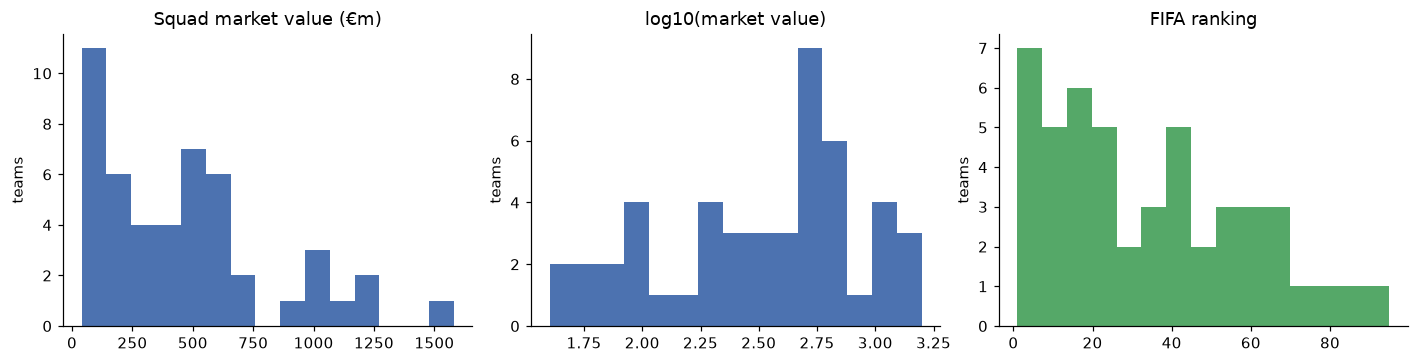

In [15]:
fig, ax = plt.subplots(1, 3, figsize=(13, 3.4))
num.market_value_m.plot.hist(bins=15, ax=ax[0], color="#4C72B0", title="Squad market value (€m)")
np.log10(num.market_value_m).plot.hist(bins=15, ax=ax[1], color="#4C72B0", title="log10(market value)")
num.fifa_rank.plot.hist(bins=15, ax=ax[2], color="#55A868", title="FIFA ranking")
for a in ax: a.set_ylabel("teams")
plt.tight_layout()

Market value is **strongly right-skewed**: it ranges from €40m to €1,580m, with a median of €415m. A few very expensive squads dominate. We therefore work with **ranks** (Spearman) and **log(value)** rather than raw values. The values are also rounded (mostly to €5–10m), which creates ties.

In [16]:
print("Ties in market value:")
print(num[num.market_value_m.duplicated(keep=False)].groupby("market_value_m").Team.apply(list).sort_index(ascending=False))

Ties in market value:
market_value_m
1250                  [Spain, England]
980     [Argentina, Portugal, Germany]
650                   [Mexico, Norway]
620                 [Morocco, Turkiye]
580                   [Uruguay, Japan]
480      [South Korea, Canada, Sweden]
200                [Tunisia, Paraguay]
55                     [Iraq, Curacao]
Name: Team, dtype: object


In [17]:
print("Sum of championship probabilities: %.1f %%" % num.p_champion_pct.sum())

Sum of championship probabilities: 142.9 %


**Finding 3:** The title probabilities sum to **142.9%** instead of 100%. This is the bookmaker margin (overround): they are not fair probabilities. For **rank comparisons** (Spearman) this does not matter. Anyone reading them as true probabilities must normalise them first (÷ sum).

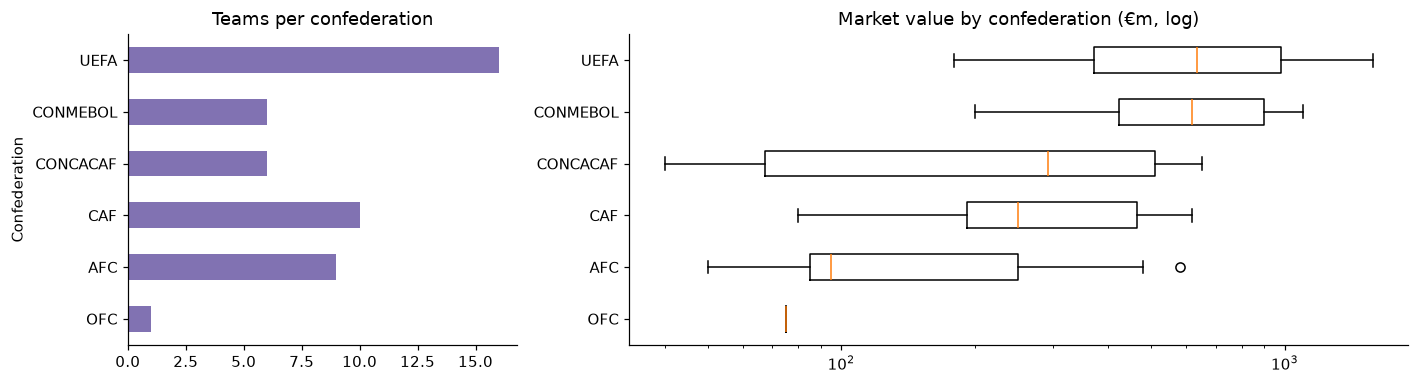

In [18]:
order = num.groupby("Confederation").market_value_m.median().sort_values().index
fig, ax = plt.subplots(1, 2, figsize=(13, 3.6), gridspec_kw={"width_ratios": [1, 2]})
num.Confederation.value_counts().reindex(order).plot.barh(ax=ax[0], color="#8172B2", title="Teams per confederation")
ax[1].boxplot([num.loc[num.Confederation == c, "market_value_m"] for c in order], tick_labels=order, orientation="horizontal")
ax[1].set_xscale("log"); ax[1].set_title("Market value by confederation (€m, log)")
plt.tight_layout()

UEFA provides 16 of the 48 teams and has the most expensive squads. OFC has a single team (New Zealand). Sample sizes for comparisons between confederations are therefore small: no robust statements are possible for OFC, nor for CONMEBOL and CONCACAF with 6 teams each.

## 5. Relationships between predictors

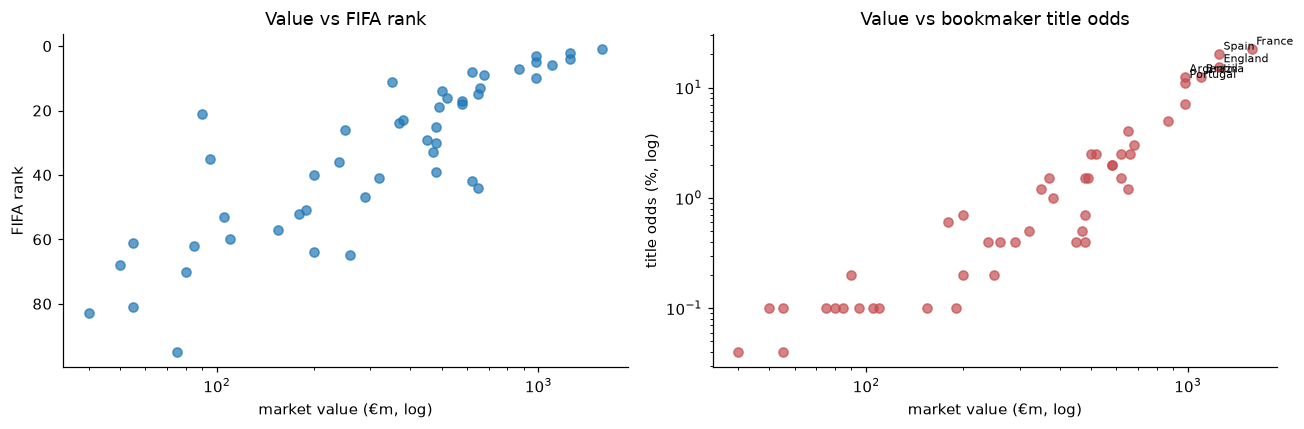

In [19]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].scatter(num.market_value_m, num.fifa_rank, alpha=.7)
ax[0].set(xscale="log", xlabel="market value (€m, log)", ylabel="FIFA rank", title="Value vs FIFA rank")
ax[0].invert_yaxis()
ax[1].scatter(num.market_value_m, num.p_champion_pct, alpha=.7, color="#C44E52")
ax[1].set(xscale="log", yscale="log", xlabel="market value (€m, log)", ylabel="title odds (%, log)", title="Value vs bookmaker title odds")
for _, r in num.nlargest(6, "market_value_m").iterrows():
    ax[1].annotate(r.Team, (r.market_value_m, r.p_champion_pct), fontsize=7, xytext=(3, 3), textcoords="offset points")
plt.tight_layout()

In [20]:
num[["market_value_m", "fifa_rank", "p_champion_pct", "p_qualify_group_pct", "wc_appearances"]].corr("spearman").round(2)

,market_value_m,fifa_rank,p_champion_pct,p_qualify_group_pct,wc_appearances
market_value_m,1.00,-0.87,0.95,0.95,0.79
fifa_rank,-0.87,1.00,-0.86,-0.92,-0.77
p_champion_pct,0.95,-0.86,1.00,0.93,0.76
p_qualify_group_pct,0.95,-0.92,0.93,1.00,0.81
wc_appearances,0.79,-0.77,0.76,0.81,1.00


The three predictors are closely related (|ρ| ≈ 0.87–0.95). Market value, FIFA ranking and odds largely measure the same thing: team strength. For the analysis this means they would be highly collinear in a joint model, so we compare each one **separately** with the stage reached.

## 6. Matches: goals & results

goals per match: mean 2.96, median 3, max 10


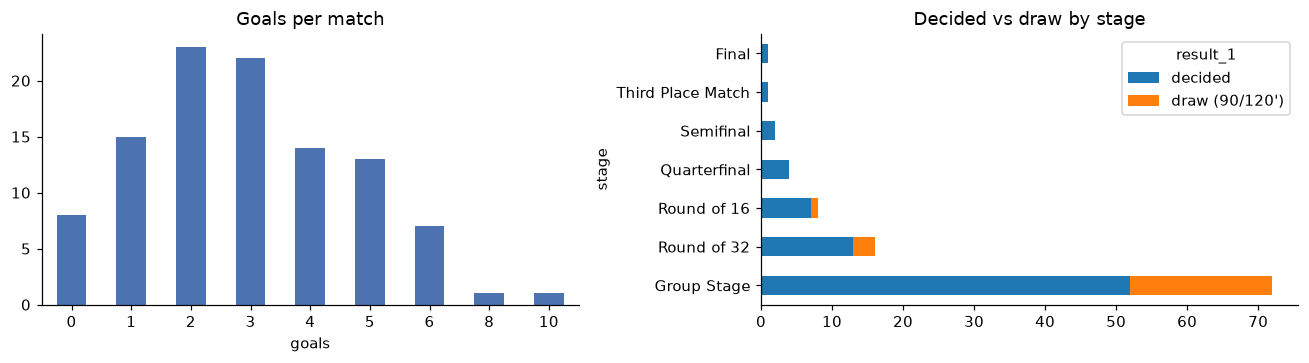

In [21]:
m = bd.load_matches()
m["goals"] = m.score_1 + m.score_2
print("goals per match: mean %.2f, median %d, max %d" % (m.goals.mean(), m.goals.median(), m.goals.max()))
fig, ax = plt.subplots(1, 2, figsize=(12, 3.4))
m.goals.value_counts().sort_index().plot.bar(ax=ax[0], color="#4C72B0", title="Goals per match", rot=0)
pd.crosstab(m.stage, m.result_1.replace({"W": "decided", "L": "decided", "D": "draw (90/120')"})
            ).reindex(expected).plot.barh(stacked=True, ax=ax[1], title="Decided vs draw by stage")
plt.tight_layout()

In [22]:
v = pre.assign(Team=pre.Team.replace(bd.NAME_FIX)).set_index("Team")["Squad Market Value (€m)"]
m["value_1"], m["value_2"] = m.team_1.map(v), m.team_2.map(v)
m["value_gap"] = m[["value_1", "value_2"]].max(axis=1) / m[["value_1", "value_2"]].min(axis=1)
print("value mapped for every match:", m[["value_1", "value_2"]].notna().all().all())
m.groupby(m.stage.ne("Group Stage").map({False: "group", True: "knockout"})).value_gap.describe().round(2)

value mapped for every match: True


,count,mean,std,min,25%,50%,75%,max
stage,,,,,,,,
group,72.0,5.35,5.63,1.02,2.01,3.13,6.86,28.73
knockout,32.0,2.71,2.34,1.26,1.36,1.91,2.82,12.25


The value gap between two opponents (richer ÷ poorer squad) is much larger in the group stage than in the knockouts. In the late rounds, almost only similarly valued teams meet. The core story builds on this; the actual analysis is in `src/analysis.py`.

## 7. Cleaning

All steps live in `src/build_dataset.py` and are documented in `docs/decisions.md`:

| # | Step | Reason |
|---|---|---|
| 1 | `Bosnia & Herz.` → `Bosnia and Herzegovina` | Finding 1: join key |
| 2 | Rename columns (snake_case), drop derived columns | Readability, redundancy |
| 3 | Join the two team sources, validated 1:1, no NAs | Integrity |
| 4 | Derive stage reached from the match list | Finding 2: wrong label for South Africa |
| 5 | Result after 90/120 min (shoot-out = draw), `progressed` = actual winner | Separate match result from progression |
| 6 | Group points, goal difference and goals per team | Extra metrics |
| 7 | `value_rank` (ties broken by FIFA ranking), `value_share_pct` | Rank comparison |
| 8 | Assert 48/32/16/8/4/2/1 teams per stage | Check against the tournament format |

The cell below runs the script. It rewrites `data/processed/teams.csv` and `matches.csv` (deterministic, same content).

In [23]:
bd.main()
teams = pd.read_csv(ROOT / "data" / "processed" / "teams.csv")
mclean = pd.read_csv(ROOT / "data" / "processed" / "matches.csv")
print(teams.shape, mclean.shape)
teams.head(10)

wrote 48 teams, 104 matches
(48, 22) (104, 13)


,team,group,confederation,fifa_rank,market_value_m,p_qualify_group_pct,p_champion_pct,wc_appearances,world_titles,debut,star_player,pre_category,host_nation,stage_reached,group_pts,group_gd,matches,gf,ga,stage_name,value_rank,value_share_pct
0,France,I,UEFA,1,1580,93,22.2,16,2,No,Kylian Mbappe,Favorite,No,5,9,8,8,20,10,Semifinal,1,7.141243
1,Spain,H,UEFA,2,1250,92,20.0,16,1,No,Lamine Yamal,Favorite,No,7,7,5,8,14,1,Champion,2,5.649718
2,England,L,UEFA,4,1250,90,15.4,17,1,No,Jude Bellingham,Favorite,No,5,7,4,8,20,12,Semifinal,3,5.649718
3,Brazil,C,CONMEBOL,6,1100,90,12.5,23,5,No,Vinicius Jr,Strong Contender,No,3,7,6,5,10,4,Round of 16,4,4.971751
4,Argentina,J,CONMEBOL,3,980,88,12.5,19,3,No,Lionel Messi,Strong Contender,No,6,9,7,8,19,8,Final,5,4.429379
5,Portugal,K,UEFA,5,980,90,11.1,9,0,No,Cristiano Ronaldo,Strong Contender,No,3,5,5,5,8,3,Round of 16,6,4.429379
6,Germany,E,UEFA,10,980,92,7.1,20,4,No,Florian Wirtz,Strong Contender,No,2,6,6,4,11,5,Round of 32,7,4.429379
7,Netherlands,F,UEFA,7,870,88,5.0,11,0,No,Virgil van Dijk,Strong Contender,No,2,7,6,4,11,5,Round of 32,8,3.932203
8,Belgium,G,UEFA,9,680,80,3.0,16,0,No,Kevin De Bruyne,Possible,No,4,5,4,6,14,7,Quarterfinal,9,3.073446
9,Colombia,K,CONMEBOL,13,660,78,2.5,7,0,No,Luis Diaz,Possible,No,3,7,3,5,5,1,Round of 16,10,2.983051


In [24]:
# Post-cleaning checks
assert len(teams) == 48 and teams.team.is_unique
assert teams.notna().all().all(), "unexpected NAs in teams"
assert teams.value_rank.tolist() == list(range(1, 49))
assert (teams.matches >= 3).all() and teams.group_pts.between(0, 9).all()
assert teams.gf.sum() == teams.ga.sum() == (mclean.score_1 + mclean.score_2).sum()
assert teams.loc[teams.team == "South Africa", "stage_name"].item() == "Round of 32"
print("all checks passed")
teams.stage_name.value_counts().reindex(bd.STAGES).to_frame("teams")

all checks passed


,teams
stage_name,
Group Stage,16
Round of 32,16
Round of 16,8
Quarterfinal,4
Semifinal,2
Final,1
Champion,1


## Summary

- **Data:** 48 teams × 12 pre-tournament attributes and 104 matches. After cleaning there are no missing values and no duplicates.
- **Three data issues found and handled:**
  1. Mismatched team name for Bosnia
  2. Wrong `eliminated_round` for South Africa (they did play the Round of 32)
  3. Bookmaker odds include a margin (sum 143%). Harmless for rank comparisons.
- **Keep in mind for the analysis:**
  - Market value is right-skewed → use ranks or log.
  - The predictors are highly correlated.
  - Some confederations have a small n.
  - This is a single tournament, so the data show association, not causation.